# 06 · From the NAO to winter extremes

**Question for this notebook.** In the real world, a positive winter NAO brings stronger westerly
winds: milder and wetter weather to northern Europe, drier weather to the south. Do the two EERIE
models reproduce that link for winter *extremes* (the wettest day, the rain on very wet days, the
mildest day), with the right sign, pattern and strength?

This is the centrepiece of the project: it connects the large-scale circulation (notebook 04) to
the regional extremes (notebook 05).

**Data.** 29 winters, 1986–2014 (the winters that have daily data).
- NAO index per winter, from notebook 04.
- Winter RX1day, winter R95p and winter TXx at every grid cell, from notebook 05.
- Four datasets: ERA5 (reanalysis reference), E-OBS (station-based, land only), ICON-ESM-ER and
  IFS-FESOM2-SR.

**Which NAO goes with which extremes.** Each model's extremes are related to *that model's own* NAO
winters. ERA5 and E-OBS extremes are both related to the ERA5 NAO, because they describe the same
real winters.

**Method** (fixed in `docs/methods.md` before any result was produced):
1. Remove the straight-line trend from both the NAO index and the extreme index, so that a shared
   long-term drift (for example warming) cannot masquerade as an NAO effect.
2. At every grid cell, compute the correlation with the NAO and the regression slope: the change
   in the extreme index per one standard deviation of NAO.
3. Test each cell (two-sided t-test) and then apply false-discovery-rate control across all cells,
   so that the map is not littered with chance "significant" dots.
4. As a simpler cross-check, compare the ten most positive with the ten most negative NAO winters.

**The NAO index used.** Notebook 04 showed that ICON-ESM-ER's own leading pressure pattern is a
mixture and not a clean NAO. So the main analysis measures every dataset along the *same* pattern,
the ERA5 NAO pattern, in units of the ERA5 standard deviation. Section 8 repeats the key numbers
with two other index definitions to show how much the choice matters.

**Sections**
1. Setup
2. Findings
3. The sample: 29 winters
4. Context: the NAO and ordinary winter rainfall
5. NAO and the wettest winter day (RX1day)
6. NAO and rain on very wet winter days (R95p)
7. NAO and the mildest winter day (TXx)
8. Regional numbers for UK and Ireland, and sensitivity to the index definition
9. Positive against negative NAO winters
10. Saved outputs
11. Limitations
12. What to check

## Background: the terms used in this notebook

If you know these already, skip to section 1.

| Term | What it means here |
|---|---|
| **Correlation (r)** | How consistently two things vary together from winter to winter, from −1 to +1. r = +0.6 between NAO and RX1day at a place means wet-extreme winters there tend to be positive-NAO winters. It says nothing about how big the effect is. |
| **Regression slope** | How big the effect is: the change in the extreme index for a one-standard-deviation increase in the NAO. For example "+4 mm per SD". |
| **Per 1 SD of NAO** | One standard deviation of the ERA5 winter NAO index, the same yardstick for every dataset. A typical positive winter is about +1 SD. |
| **Detrending** | Subtracting the best-fit straight line over 1986–2014 from each series before correlating them. |
| **p value** | The probability of seeing a correlation at least this strong purely by chance if there were no real link. Small is convincing; below 0.05 is the usual threshold. |
| **Multiple testing** | A map has thousands of grid cells. Testing each at the 5% level would flag about 5% of them even if the NAO had no effect anywhere. |
| **False-discovery-rate (FDR) control** | A standard correction for that problem (Benjamini–Hochberg; recommended for climate maps by Wilks 2016). It raises the bar so that, among the cells finally marked, only a small expected share (here 10%) are false alarms. Dots on the maps mark cells that pass it. |
| **Composite** | The average over a group of winters. "NAO+ minus NAO−" is the average of the ten most positive winters minus the average of the ten most negative. |
| **Bootstrap interval** | An uncertainty range obtained by re-drawing the winters many times at random. If the range excludes zero, the difference is unlikely to be chance. |
| **Pattern correlation** | How similar the shapes of two maps are, from −1 to 1. Used here to ask: does the model's NAO-response map look like the reference's? |

**How to read the maps.** All maps in this notebook show a *response to the NAO*. Orange means the
index goes **up** in positive-NAO winters, blue means it goes **down**, grey means no link.
Small dots mark grid cells where the link passes the significance test with FDR control.
All panels of one figure share one colour scale. E-OBS is blank over sea.

**Colours of the points and lines.** Dark grey ERA5, light grey E-OBS, blue ICON-ESM-ER, orange
IFS-FESOM2-SR.

> **Note on ERA5 daily data.** When this notebook was last run, the ERA5 *daily* files were not yet
> fully downloaded (the internet connection was too slow), so E-OBS is the only reference here.
> E-OBS is the more direct reference for extremes over land in any case. The notebook picks up
> ERA5 automatically, as a second reference, once `data/era5/day/` holds all 30 years: just run it again.

## 1. Setup

**What this cell does.** Loads the project code. The statistics are in `eerie_uk/relationships.py`;
each function has a unit test on synthetic data where the true answer is known.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from pathlib import Path
from eerie_uk import climatology as clim, extremes as ex, plotting, regions, relationships as rel, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
MODELS = ['icon-esm-er', 'ifs-fesom2-sr']
REFS = ['e-obs']      # reference datasets
DATASETS = REFS + MODELS
NAO_OF = {'e-obs': 'era5', 'era5': 'era5', 'icon-esm-er': 'icon-esm-er', 'ifs-fesom2-sr': 'ifs-fesom2-sr'}
NAME = plotting.SOURCE_LABELS
WINTERS = (1986, 2014)

**What this cell does.** Loads the two inputs: the winter NAO indices saved by notebook 04 and the
gridded winter extreme indices cached by notebook 05. E-OBS is put on the model grid, and a land
mask is built for land-only statistics.

In [2]:
nao_table = pd.read_parquet('../app_assets/nao_index_winter.parquet')

def nao_index(source, column='nao_on_era5_pattern'):
    part = nao_table[(nao_table.source == source) & nao_table.year.between(*WINTERS)]
    return xr.DataArray(part[column].values, coords={'year': part.year.values}, dims='year')

indices = {d: ex.indices_for(d) for d in DATASETS}
grid = indices['icon-esm-er']
indices['e-obs'] = regions.to_grid(indices['e-obs'], grid)
land = regions.land_mask(grid.lat, grid.lon)

def winter_field(dataset, name):
    return indices[dataset][f'{name}_djf'].rename(year_djf='year')

print('winters:', WINTERS[0], 'to', WINTERS[1], '=', nao_index('era5').size)

winters: 1986 to 2014 = 29


## 2. Findings

29 winters, 1986–2014. One member per model. Reference for extremes: E-OBS (land), paired with the ERA5 NAO. All series detrended. "Per SD" means per one standard deviation of the ERA5 NAO.

**UK and Ireland, land average: link between the winter NAO and winter extremes**

| | E-OBS (real world) | ICON-ESM-ER | IFS-FESOM2-SR |
|---|---|---|---|
| Wettest winter day (RX1day): correlation | **0.56** | 0.28 | **0.57** |
| … change per SD of NAO (95% range) | +1.3 mm (0.6 to 2.1) | +1.6 mm (−0.6 to 3.9) | +2.7 mm (1.2 to 4.3) |
| Very-wet-day rain (R95p): correlation | **0.51** | 0.36 | **0.60** |
| … change per SD of NAO (95% range) | +10 mm (3 to 18) | +17 mm (−1 to 35) | +17 mm (8 to 25) |
| Mildest winter day (TXx): correlation | 0.32 | 0.21 | 0.12 |
| Ten most positive minus ten most negative NAO winters, R95p | +27 mm (11 to 43) | +20 mm (−1 to 41) | +27 mm (8 to 45) |

Bold: distinguishable from zero at the 5% level.

**What this means, in plain words**

1. **The real-world link is clear for rainfall extremes.** In E-OBS, positive-NAO winters over UK and Ireland have a wetter wettest day and markedly more rain on very wet days: about +10 mm of very-wet-day rain per SD of NAO, against a winter average of 49 mm. The ten most positive NAO winters had about 27 mm more than the ten most negative. The link is much stronger in western Norway (correlation about 0.8).
2. **Both models reproduce the textbook response of ordinary winter rainfall** (Figure 1): wetter in the north, drier in the south in positive-NAO winters. This is the precondition for the rest.
3. **IFS-FESOM2-SR reproduces the NAO link to rainfall extremes over UK and Ireland,** with the right sign, similar correlations (0.57 and 0.60 against 0.56 and 0.51) and a response per SD that is as large as observed or larger. Its uncertainty ranges overlap the observed ones. Its composite difference (+27 mm) matches E-OBS. It also has the right sign in western Norway and north-west France.
4. **ICON-ESM-ER has the right sign over UK and Ireland but a weaker, less consistent link** (correlations 0.28 and 0.36); its ranges include zero, so with 29 winters the link cannot be distinguished from chance. In western Norway its link is positive and significant. In north-west France it has the **opposite sign** to E-OBS for very-wet-day rain (−0.46 against +0.34): in this model the dry side of the NAO reaches too far north (visible in Figure 1, where its blue area covers France).
5. **The mildest winter day (TXx) shows only a weak NAO link over UK and Ireland, in the real world too** (0.32, not significant), and neither model shows one. E-OBS does show a clear link over Scandinavia and central Europe, which neither model reproduces in pattern (pattern correlations about 0.2). Winter TXx is the least well captured of the three.
6. **On maps, the model responses resemble the observed one best for R95p** (pattern correlation with E-OBS over land: 0.58 for ICON-ESM-ER, 0.66 for IFS-FESOM2-SR), less for RX1day (0.32 and 0.44). Very few model grid cells pass the significance test with FDR control, against 8–16% of land cells in E-OBS. A weaker NAO (standard deviation 0.52 and 0.78 of ERA5's in these winters) gives the models less signal to detect, so fewer dots is expected and is not by itself a fault.
7. **The choice of NAO index matters for ICON-ESM-ER and not for the others.** With ICON-ESM-ER's own leading pattern the UK correlations vanish (0.02 and −0.06), which confirms the finding of notebook 04 that this pattern is not a clean NAO. With the common ERA5 pattern or the station-style index they return (0.23 to 0.40). For E-OBS and IFS-FESOM2-SR all three definitions agree.

**Answer to the question.** IFS-FESOM2-SR reproduces the sign, the regional pattern and the strength of the observed NAO link to winter rainfall extremes over UK and Ireland. ICON-ESM-ER reproduces the sign in the north but with a weaker link, and misplaces the boundary between the wet and dry sides. Neither reproduces the link to the mildest winter day. With 29 winters and one member each these are indications, not established model properties.

## 3. The sample: 29 winters

Everything below rests on 29 winters per dataset. That is a small sample for a noisy link, and it
is stated here once: with 29 winters and detrended series, a correlation needs to exceed about
±0.38 to pass an ordinary 5% test at a single place, and more than that after FDR control.

**What this cell does.** Describes the NAO sample of each dataset over these 29 winters: the spread
of the index (in ERA5 standard deviations), and the index range of the ten most positive and ten
most negative winters used later for composites.

In [3]:
rows = []
for s in ('era5',) + tuple(MODELS):
    series = nao_index(s).to_series()
    rows.append({'NAO from': NAME[s], 'winters': series.size, 'standard deviation': series.std(),
                 'most positive': series.max(), 'most negative': series.min(),
                 'mean of top 10': series.nlargest(10).mean(), 'mean of bottom 10': series.nsmallest(10).mean()})
pd.DataFrame(rows)

,NAO from,winters,standard deviation,most positive,most negative,mean of top 10,mean of bottom 10
0,ERA5,29,1.04,2.16,-2.53,1.41,-0.77
1,ICON-ESM-ER,29,0.52,1.08,-1.15,0.65,-0.42
2,IFS-FESOM2-SR,29,0.78,1.68,-1.55,0.91,-0.75


**Why the standard deviations differ.** The index is in ERA5 units. A model whose NAO is weaker
than ERA5's (notebook 04) has a standard deviation below 1 here. Its NAO winters are therefore
less extreme, and the *same* slope per SD produces smaller winter-to-winter swings in that model.

## 4. Context: the NAO and ordinary winter rainfall

Before extremes, the textbook link: a positive NAO makes the whole winter wetter in the north and
drier in the south. If a model does not show this, there is little point asking about extremes.

**What this cell does.** Regresses winter-mean precipitation (from the monthly data) on the NAO at
every grid cell, for ERA5 and the two models. Dots mark cells that pass the FDR-controlled test.

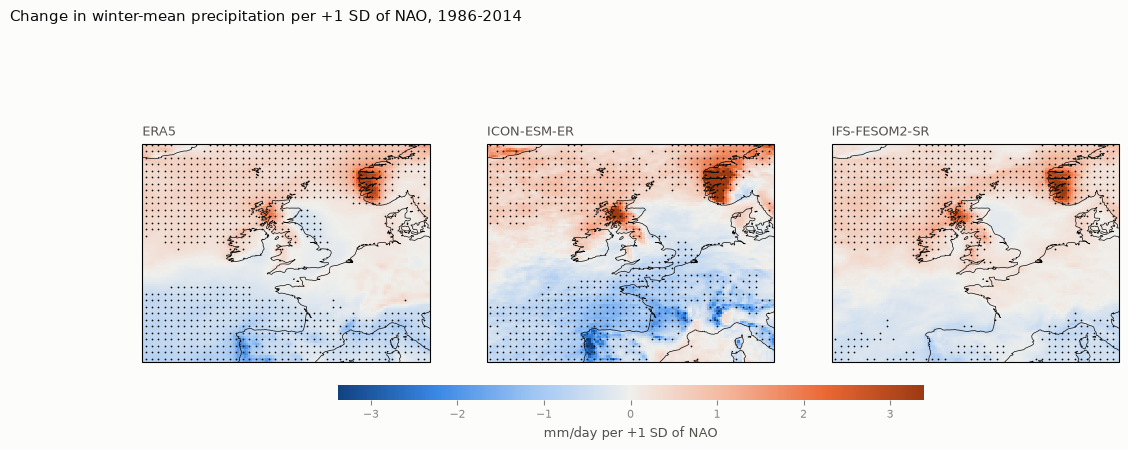

In [4]:
context, context_mask = {}, {}
for s in ('era5',) + tuple(MODELS):
    winter_pr = clim.season_means(store.load(s, 'mon', 'pr', 'nw_europe'), 'DJF').sel(year=slice(*WINTERS))
    result = rel.correlate(winter_pr, nao_index(s))
    context[NAME[s]] = result.slope
    context_mask[NAME[s]] = rel.fdr_mask(result.p)
plotting.plot_field_panels(context, units='mm/day per +1 SD of NAO', diverging=True, stipple=context_mask,
                           title='Change in winter-mean precipitation per +1 SD of NAO, 1986-2014');

**Figure 1.** The response of ordinary winter rainfall to the NAO. Orange: wetter in positive-NAO
winters; blue: drier. The expected picture is orange over Scotland, Norway and the northern seas
and blue over Iberia and the Mediterranean, with the dividing line near 50°N.

**What this cell does.** Defines the function used for the three extreme indices below. For one
index it computes, for each of the four datasets, the correlation map, the slope map and the
FDR-significant cells, and collects summary numbers: the share of land cells that are significant
and how closely each model's response map resembles each reference's (pattern correlation, land).

In [5]:
def analyse(name):
    out = {}
    for d in DATASETS:
        result = rel.correlate(winter_field(d, name), nao_index(NAO_OF[d]))
        result['significant'] = rel.fdr_mask(result.p)
        out[d] = result
    return out

def summarise(results):
    rows = []
    for d in DATASETS:
        r = results[d]
        row = {'dataset': NAME[d], 'land cells significant %': 100 * float(r.significant.where(land).mean()),
               'mean |r| over land': float(abs(r.r).where(land).mean())}
        for ref in REFS:
            both = land & r.slope.notnull() & results[ref].slope.notnull()
            row[f'pattern correlation with {NAME[ref]}'] = clim.pattern_stats(r.slope.where(both), results[ref].slope.where(both))['pattern correlation']
        rows.append(row)
    return pd.DataFrame(rows)

def maps(results, variable, units, title, limit=None):
    plotting.plot_field_panels({NAME[d]: results[d][variable] for d in DATASETS}, units=units, title=title, columns=2,
                               diverging=True, stipple={NAME[d]: results[d].significant for d in DATASETS}, limit=limit)

## 5. NAO and the wettest winter day (RX1day)

**What this cell does.** Maps the correlation between the winter NAO and winter RX1day for the four
datasets. The colour scale is fixed at ±1.

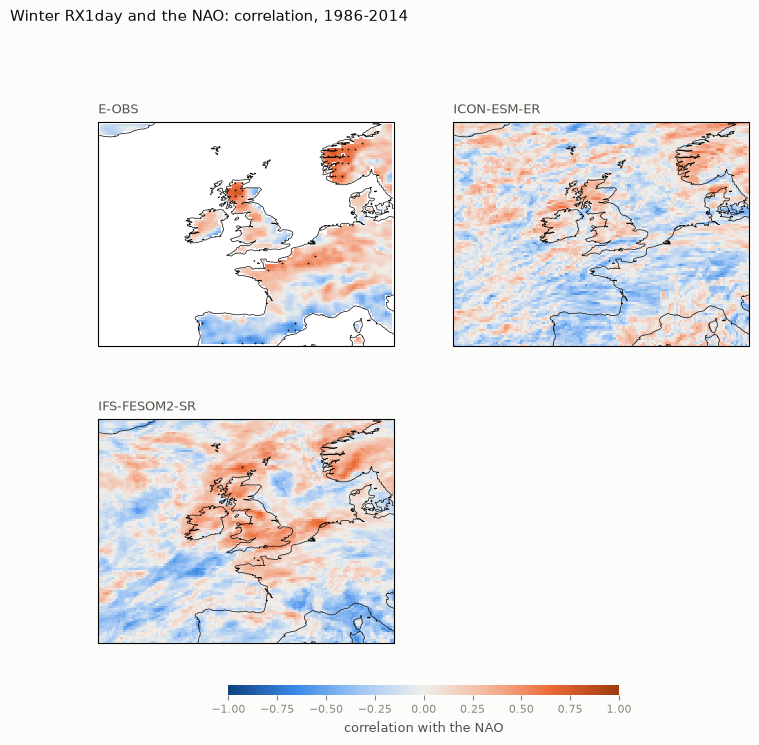

In [6]:
rx = analyse('rx1day')
maps(rx, 'r', 'correlation with the NAO', 'Winter RX1day and the NAO: correlation, 1986-2014', limit=1.0)

**Figure 2.** Correlation of the wettest winter day with the NAO. Orange: the wettest day tends to
be wetter in positive-NAO winters. Dots: significant after FDR control. Reference dataset(s) first, then the two models.

**What this cell does.** Maps the size of the effect: the change in winter RX1day, in mm, per +1 SD
of NAO.

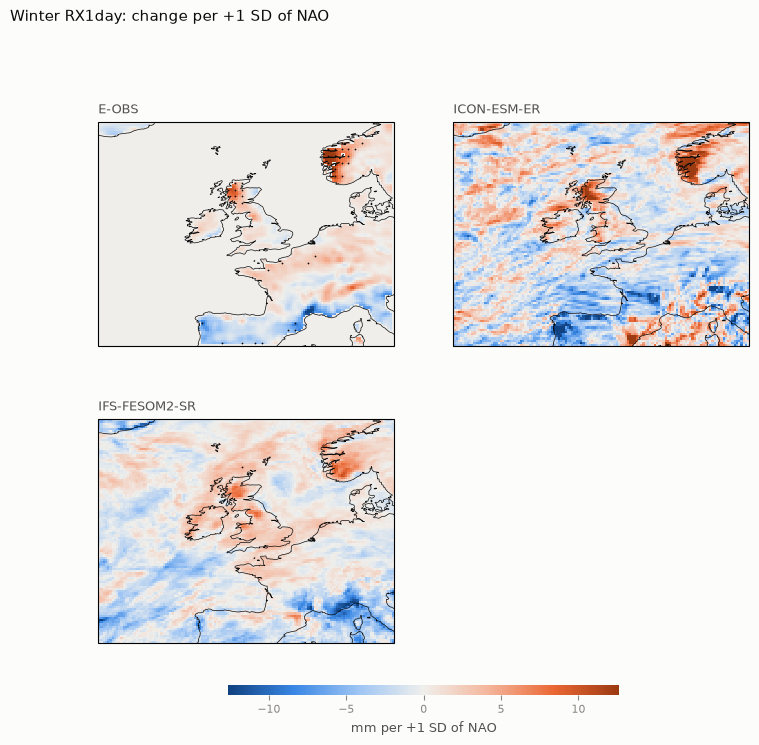

In [7]:
maps(rx, 'slope', 'mm per +1 SD of NAO', 'Winter RX1day: change per +1 SD of NAO')

**Figure 3.** Size of the NAO effect on the wettest winter day. Compare the model panels with the
reference: same places, same sign, similar strength?

**What this cell does.** Summarises the four maps in numbers.

In [8]:
rx_summary = summarise(rx)
rx_summary

,dataset,land cells significant %,mean |r| over land,pattern correlation with E-OBS
0,E-OBS,7.98,0.25,1.00
1,ICON-ESM-ER,0.00,0.18,0.32
2,IFS-FESOM2-SR,0.00,0.19,0.44


## 6. NAO and rain on very wet winter days (R95p)

**What this cell does.** The same correlation map for winter R95p: the rain that falls on days
above the local very-wet-day threshold.

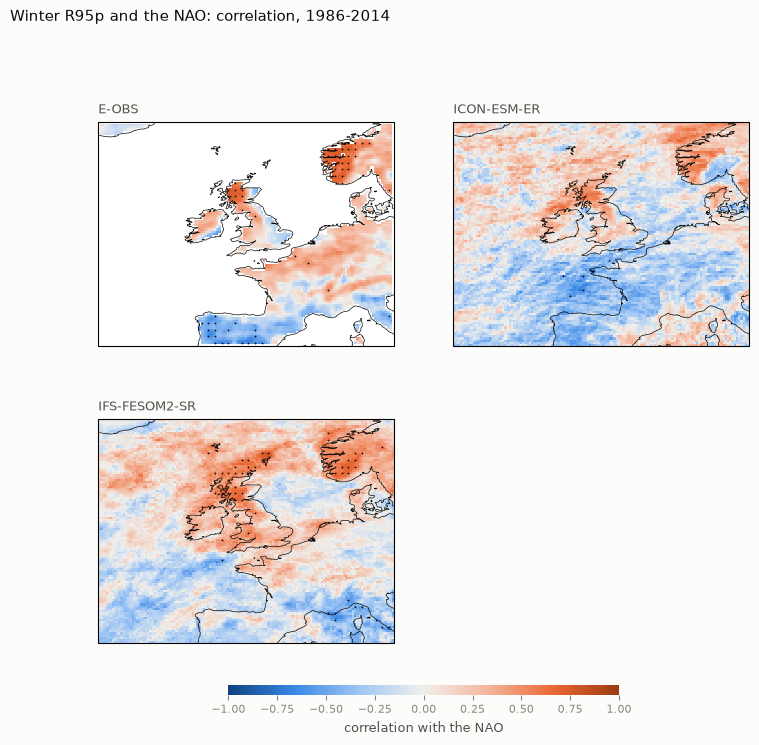

In [9]:
r95 = analyse('r95p')
maps(r95, 'r', 'correlation with the NAO', 'Winter R95p and the NAO: correlation, 1986-2014', limit=1.0)

**Figure 4.** Correlation of very-wet-day rainfall with the NAO. R95p adds up several days per
winter, so it is less noisy than the single wettest day and usually shows the NAO more clearly.

**What this cell does.** The size of the effect, in mm of very-wet-day rain per winter per +1 SD of
NAO, and the summary numbers.

,dataset,land cells significant %,mean |r| over land,pattern correlation with E-OBS
0,E-OBS,11.34,0.28,1.00
1,ICON-ESM-ER,0.04,0.24,0.58
2,IFS-FESOM2-SR,5.22,0.22,0.66


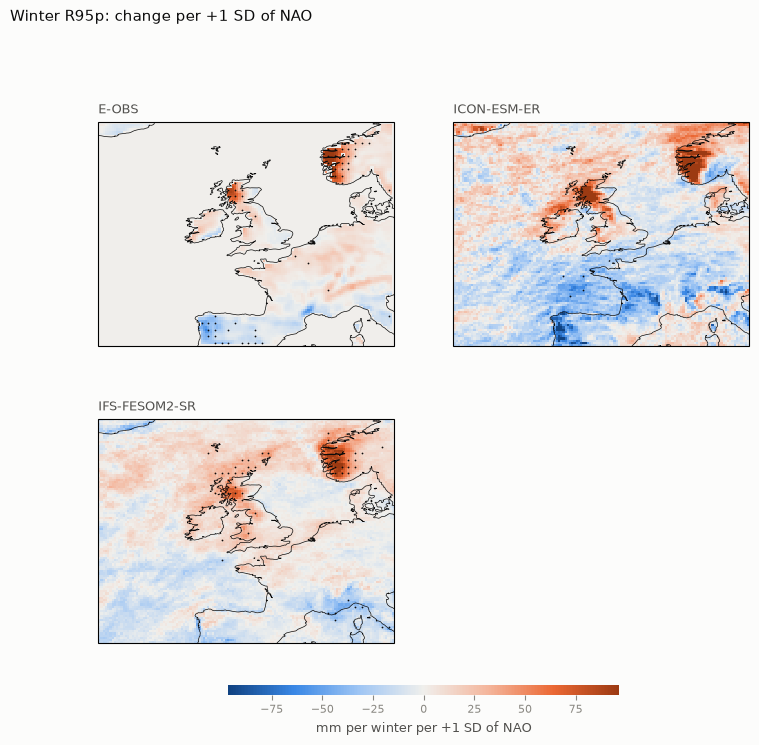

In [10]:
maps(r95, 'slope', 'mm per winter per +1 SD of NAO', 'Winter R95p: change per +1 SD of NAO')
r95_summary = summarise(r95)
r95_summary

**Figure 5.** Size of the NAO effect on very-wet-day rainfall.

## 7. NAO and the mildest winter day (TXx)

**What this cell does.** The correlation map for winter TXx: the highest daily maximum temperature
of the winter.

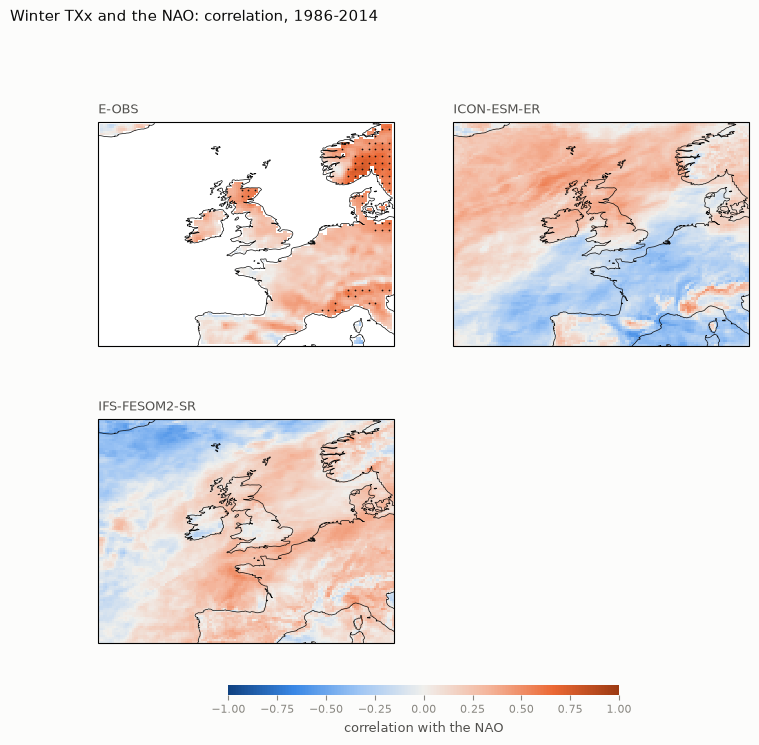

In [11]:
tx = analyse('txx')
maps(tx, 'r', 'correlation with the NAO', 'Winter TXx and the NAO: correlation, 1986-2014', limit=1.0)

**Figure 6.** Correlation of the mildest winter day with the NAO. A positive NAO brings mild
Atlantic air into northern Europe, so orange is expected there.

**What this cell does.** The size of the effect, in °C per +1 SD of NAO, and the summary numbers.

,dataset,land cells significant %,mean |r| over land,pattern correlation with E-OBS
0,E-OBS,15.68,0.28,1.00
1,ICON-ESM-ER,0.00,0.20,0.20
2,IFS-FESOM2-SR,0.00,0.19,0.17


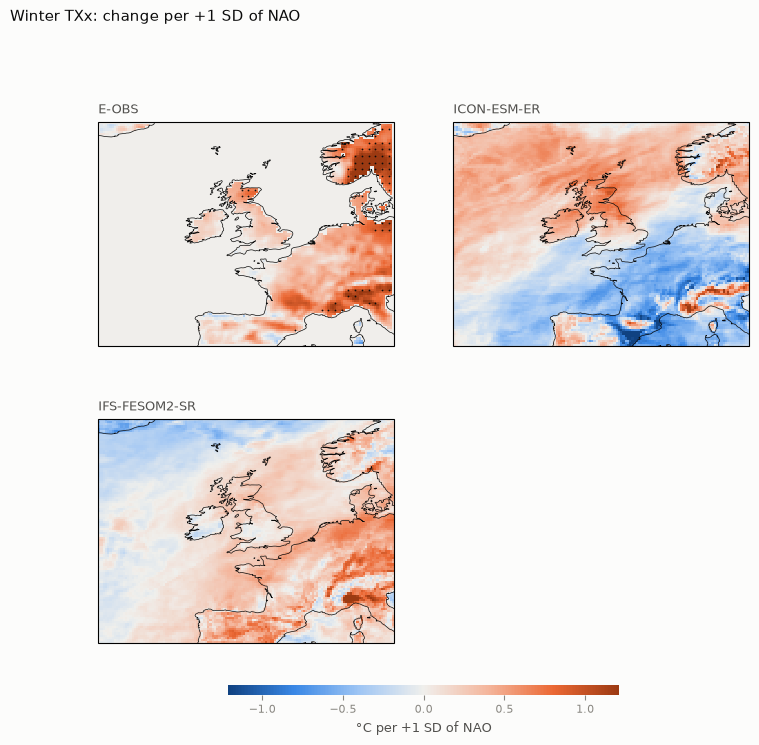

In [12]:
maps(tx, 'slope', '°C per +1 SD of NAO', 'Winter TXx: change per +1 SD of NAO')
tx_summary = summarise(tx)
tx_summary

**Figure 7.** Size of the NAO effect on the mildest winter day.

## 8. Regional numbers for UK and Ireland, and sensitivity to the index definition

**What this cell does.** Moves from maps to the headline region. It takes the land-average winter
series saved by notebook 05 and, for each dataset and index, computes the correlation with the NAO,
the slope per SD with its 95% range, and the p value. Western Norway and north-west France are
included as supporting regions on the wet and dry sides of the NAO.

In [13]:
regional = pd.read_parquet('../app_assets/extremes_regional.parquet')
regional = regional[(regional.period == 'winter') & regional.year.between(*WINTERS)]
INDEX_LABELS = {'rx1day': 'RX1day (mm)', 'r95p': 'R95p (mm)', 'txx': 'TXx (°C)'}

def regional_link(column='nao_on_era5_pattern'):
    rows = []
    for region in regions.SUBREGIONS:
        for key, label in INDEX_LABELS.items():
            for d in DATASETS:
                part = regional[(regional.region == region) & (regional['index'] == key) & (regional.source == d)].sort_values('year')
                fit = rel.regress_series(part.value.values, nao_index(NAO_OF[d], column).sel(year=part.year.values).values)
                rows.append({'region': regions.LABELS[region], 'index': label, 'dataset': NAME[d], **fit})
    return pd.DataFrame(rows)

link = regional_link()
link[link.region == 'UK and Ireland'].drop(columns='region').reset_index(drop=True)

,index,dataset,r,slope,low,high,p
0,RX1day (mm),E-OBS,0.56,1.34,0.56,2.11,0.00
1,RX1day (mm),ICON-ESM-ER,0.28,1.63,-0.61,3.87,0.15
2,RX1day (mm),IFS-FESOM2-SR,0.57,2.73,1.16,4.31,0.00
3,R95p (mm),E-OBS,0.51,10.47,3.42,17.52,0.01
4,R95p (mm),ICON-ESM-ER,0.36,17.30,-0.68,35.28,0.06
5,R95p (mm),IFS-FESOM2-SR,0.60,16.66,7.93,25.40,0.00
6,TXx (°C),E-OBS,0.32,0.26,-0.05,0.57,0.10
7,TXx (°C),ICON-ESM-ER,0.21,0.27,-0.21,0.75,0.27
8,TXx (°C),IFS-FESOM2-SR,0.12,0.12,-0.26,0.50,0.53


**How to read this table.** `r` is the correlation, `slope` the change per +1 SD of NAO, `low` and
`high` its 95% range, `p` the p value. If the range from `low` to `high` includes 0, the link is
not distinguishable from chance in 29 winters.

**What this cell does.** Shows the same thing as pictures for UK and Ireland winter R95p: one dot
per winter, NAO on the horizontal axis, with the fitted line. A steep, tight cloud means a strong,
consistent link.

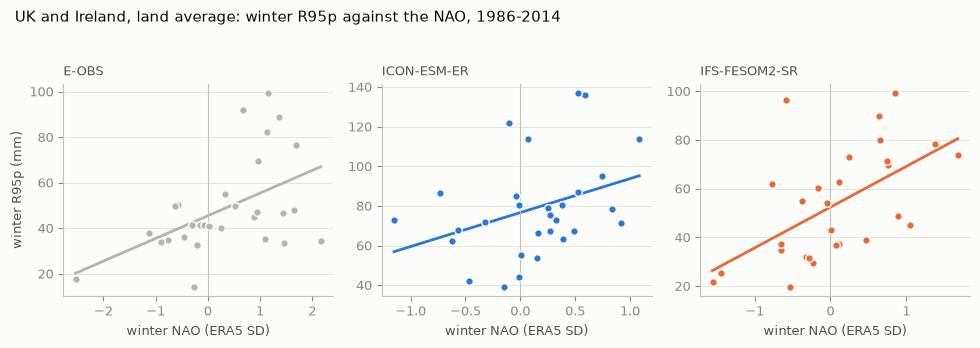

In [14]:
panels = {}
for d in DATASETS:
    part = regional[(regional.region == 'uk_ireland') & (regional['index'] == 'r95p') & (regional.source == d)].sort_values('year')
    panels[NAME[d]] = (d, nao_index(NAO_OF[d]).sel(year=part.year.values).values, part.value.values)
plotting.plot_scatter_panels(panels, xlabel='winter NAO (ERA5 SD)', ylabel='winter R95p (mm)',
                             title='UK and Ireland, land average: winter R95p against the NAO, 1986-2014');

**Figure 8.** Each dot is one winter. The lines are fitted without detrending, for display only;
the table above uses detrended series.

**What this cell does.** The supporting regions.

In [15]:
link[link.region != 'UK and Ireland'].reset_index(drop=True)

,region,index,dataset,r,slope,low,high,p
0,Western Norway,RX1day (mm),E-OBS,0.78,6.90,4.68,9.11,0.00
1,Western Norway,RX1day (mm),ICON-ESM-ER,0.46,8.15,1.88,14.43,0.01
2,Western Norway,RX1day (mm),IFS-FESOM2-SR,0.46,4.58,1.11,8.04,0.01
3,Western Norway,R95p (mm),E-OBS,0.81,55.12,39.15,71.08,0.00
4,Western Norway,R95p (mm),ICON-ESM-ER,0.52,82.38,29.19,135.57,0.00
5,Western Norway,R95p (mm),IFS-FESOM2-SR,0.66,64.23,35.47,93.00,0.00
6,Western Norway,TXx (°C),E-OBS,0.50,0.54,0.17,0.92,0.01
7,Western Norway,TXx (°C),ICON-ESM-ER,0.07,0.11,-0.57,0.80,0.74
8,Western Norway,TXx (°C),IFS-FESOM2-SR,0.16,0.16,-0.23,0.54,0.42
9,North-west France,RX1day (mm),E-OBS,0.38,1.53,0.05,3.01,0.05


**What this cell does.** A sensitivity test. It repeats the UK and Ireland correlations with two
other definitions of the NAO index: each dataset's *own* leading pattern, and the simple
station-style index (Azores minus Iceland pressure). If a conclusion holds under all three
definitions it does not depend on the choice made in this notebook.

In [16]:
alternatives = {'along the ERA5 pattern (main)': 'nao_on_era5_pattern', 'own leading pattern': 'nao_own_pattern', 'station-style': 'nao_station_style'}
table = pd.concat({label: regional_link(column).query("region == 'UK and Ireland'").set_index(['index', 'dataset']).r
                   for label, column in alternatives.items()}, axis=1)
table

along the ERA5 pattern (main)  own leading pattern  station-style
index       dataset                                                                         
RX1day (mm) E-OBS                                   0.56                 0.56           0.56
            ICON-ESM-ER                             0.28                 0.02           0.23
            IFS-FESOM2-SR                           0.57                 0.55           0.43
R95p (mm)   E-OBS                                   0.51                 0.51           0.53
            ICON-ESM-ER                             0.36                -0.06           0.40
            IFS-FESOM2-SR                           0.60                 0.67           0.43
TXx (°C)    E-OBS                                   0.32                 0.32           0.31
            ICON-ESM-ER                             0.21                 0.18           0.24
            IFS-FESOM2-SR                           0.12                 0.13           0.05

## 9. Positive against negative NAO winters

A simpler view that needs no straight-line assumption: the ten most positive NAO winters minus the
ten most negative.

**What this cell does.** For UK and Ireland (land average), computes the difference in each winter
extreme index between the ten most positive and the ten most negative NAO winters of each dataset,
with a bootstrap 95% range.

In [17]:
rows = []
for key, label in INDEX_LABELS.items():
    for d in DATASETS:
        part = regional[(regional.region == 'uk_ireland') & (regional['index'] == key) & (regional.source == d)].sort_values('year')
        result = rel.composite_interval(part.value.values, nao_index(NAO_OF[d]).sel(year=part.year.values).values)
        rows.append({'index': label, 'dataset': NAME[d], 'NAO+ minus NAO-': result['difference'], 'low': result['low'], 'high': result['high'],
                     'range excludes zero': bool(result['low'] > 0 or result['high'] < 0)})
composites = pd.DataFrame(rows)
composites

,index,dataset,NAO+ minus NAO-,low,high,range excludes zero
0,RX1day (mm),E-OBS,3.01,1.19,4.92,True
1,RX1day (mm),ICON-ESM-ER,1.07,-1.57,3.43,False
2,RX1day (mm),IFS-FESOM2-SR,4.83,1.46,8.11,True
3,R95p (mm),E-OBS,26.55,11.17,43.12,True
4,R95p (mm),ICON-ESM-ER,19.81,-1.08,41.12,False
5,R95p (mm),IFS-FESOM2-SR,27.47,8.04,44.83,True
6,TXx (°C),E-OBS,0.67,0.02,1.32,True
7,TXx (°C),ICON-ESM-ER,0.34,-0.27,0.88,False
8,TXx (°C),IFS-FESOM2-SR,0.03,-0.58,0.66,False


**What this cell does.** Maps the same composite difference for winter R95p at every grid cell, to
check that the composite picture agrees with the regression maps of section 6.

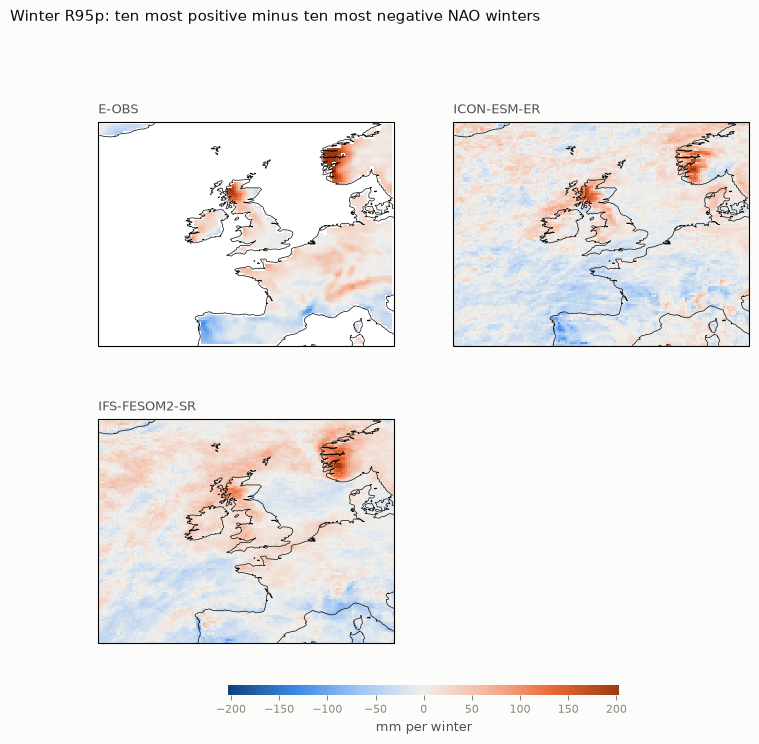

In [18]:
plotting.plot_field_panels({NAME[d]: rel.composite(winter_field(d, 'r95p'), nao_index(NAO_OF[d])) for d in DATASETS},
                           units='mm per winter', columns=2, diverging=True,
                           title='Winter R95p: ten most positive minus ten most negative NAO winters');

**Figure 9.** Composite difference in very-wet-day rainfall. Each model's composite uses that
model's own ten most positive and ten most negative winters, which are less extreme than ERA5's
if its NAO is weaker.

## 10. Saved outputs

**What this cell does.** Saves the regional link table and the composite table to `app_assets/`
for the dashboard and the summary notebook.

In [19]:
out = Path('../app_assets')
link.to_parquet(out / 'nao_extremes_regional_link.parquet', index=False)
composites.to_parquet(out / 'nao_extremes_composites.parquet', index=False)
summary = pd.concat({'RX1day': rx_summary, 'R95p': r95_summary, 'TXx': tx_summary}, names=['index']).reset_index(level=0)
summary.to_parquet(out / 'nao_extremes_map_summary.parquet', index=False)
print('saved', len(link), 'regional rows,', len(composites), 'composite rows,', len(summary), 'map-summary rows')
summary.reset_index(drop=True)

saved 27 regional rows, 9 composite rows, 9 map-summary rows


,index,dataset,land cells significant %,mean |r| over land,pattern correlation with E-OBS
0,RX1day,E-OBS,7.98,0.25,1.00
1,RX1day,ICON-ESM-ER,0.00,0.18,0.32
2,RX1day,IFS-FESOM2-SR,0.00,0.19,0.44
3,R95p,E-OBS,11.34,0.28,1.00
4,R95p,ICON-ESM-ER,0.04,0.24,0.58
5,R95p,IFS-FESOM2-SR,5.22,0.22,0.66
6,TXx,E-OBS,15.68,0.28,1.00
7,TXx,ICON-ESM-ER,0.00,0.20,0.20
8,TXx,IFS-FESOM2-SR,0.00,0.19,0.17


## 11. Limitations

- **29 winters and one member per model.** This is the main limitation. A real but moderate link
  can easily fail to reach significance, and a model can differ from the reference by chance alone.
  Absence of dots is not evidence of absence of a link.
- **The models have a weaker NAO** (notebook 04). Slopes are per ERA5 standard deviation, so they
  are comparable, but the model slopes are estimated from a narrower range of NAO values and are
  therefore less certain.
- **ICON-ESM-ER's mean state** already resembles a strong positive NAO. Its response to further NAO
  swings is measured around that biased state.
- **Linear and simultaneous.** The method assumes the response is proportional to the NAO and has
  the same size for positive and negative winters, and it looks only at the same winter.
- **Other drivers are ignored.** Other circulation patterns (for example the East Atlantic pattern)
  also affect these extremes and can strengthen or mask the NAO signal.
- **RX1day is one day per winter,** so it is the noisiest of the three indices.
- **FDR level 10%.** A common choice for spatially correlated climate fields (Wilks 2016); a
  stricter level would mark fewer cells.
- **References.** E-OBS smooths intense rain and covers land only; ERA5 rain is a model product.

## 12. What to check

1. **Figure 1:** do both models show the textbook wet-north, dry-south response of ordinary winter
   rain? This is the precondition for everything else.
2. **Figures 2–7:** for each index, do the model panels resemble the reference panels in sign and
   pattern?
3. **UK and Ireland table (section 8):** is the level of evidence stated honestly, given 29 winters?
4. **Sensitivity table:** does any conclusion depend on which NAO index is used?
5. **Next step:** the optional paired experiment (notebook 07), or go straight to the summary
   notebook, README and dashboard?